In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent

FEATURES_PATH = (
    PROJECT_ROOT /
    "data" /
    "raw" /
    "heart_disease_features.csv"
)

TARGET_PATH = (
    PROJECT_ROOT /
    "data" /
    "raw" /
    "heart_disease_target.csv"
)

X = pd.read_csv(FEATURES_PATH)
y = pd.read_csv(TARGET_PATH)

df = pd.concat([X, y], axis=1)

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [2]:
df.shape

(303, 14)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [4]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [5]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df["num"].value_counts().sort_index()

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

In [8]:
df["target"] = (df["num"] > 0).astype(int)

In [9]:
df["target"].value_counts()

target
0    164
1    139
Name: count, dtype: int64

In [10]:
df["target"].value_counts(normalize=True) * 100

target
0    54.125413
1    45.874587
Name: proportion, dtype: float64

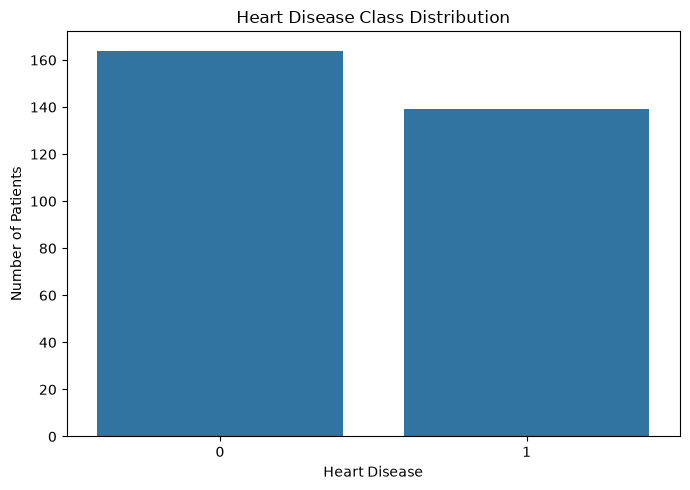

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="target"
)

plt.title("Heart Disease Class Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

In [12]:
missing = df.isnull().sum()

missing[missing > 0]

ca      4
thal    2
dtype: int64

In [13]:
missing_pct = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_pct[missing_pct > 0]

ca      1.320132
thal    0.660066
dtype: float64

In [14]:
df["target"] = (df["num"] > 0).astype(int)

print("Binary target distribution:")
print(df["target"].value_counts().sort_index())

print("\nBinary target percentage:")
print(
    (df["target"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64

Binary target percentage:
target
0    54.13
1    45.87
Name: proportion, dtype: float64


In [15]:
df[df["ca"].isna()]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
166,52,1,3,138,223,0,0,169,0,0.0,1,NaN,3.0,0,0
192,43,1,4,132,247,1,2,143,1,0.1,2,NaN,7.0,1,1
287,58,1,2,125,220,0,0,144,0,0.4,2,NaN,7.0,0,0
302,38,1,3,138,175,0,0,173,0,0.0,1,NaN,3.0,0,0


In [16]:
df[df["thal"].isna()]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
87,53,0,3,128,216,0,2,115,0,0.0,1,0.0,NaN,0,0
266,52,1,4,128,204,1,0,156,1,1.0,2,0.0,NaN,2,1


In [17]:
df[["ca", "thal"]].describe()

,ca,thal
count,299.000000,301.000000
mean,0.672241,4.734219
std,0.937438,1.939706
min,0.000000,3.000000
25%,0.000000,3.000000
50%,0.000000,3.000000
75%,1.000000,7.000000
max,3.000000,7.000000


In [18]:
df[["ca", "thal", "target"]].groupby("target").count()

,ca,thal
target,,
0,161,163
1,138,138


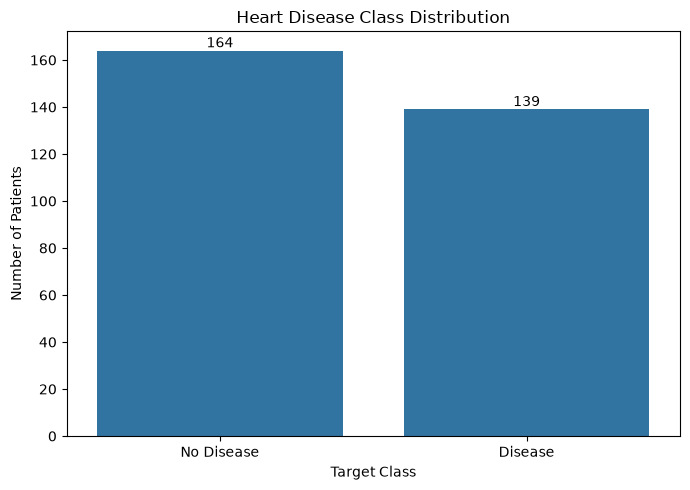

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="target"
)

plt.title("Heart Disease Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Patients")

for container in ax.containers:
    ax.bar_label(container)

plt.xticks(
    [0, 1],
    ["No Disease", "Disease"]
)

plt.tight_layout()
plt.show()

In [20]:
plt.tight_layout()

plt.savefig(
    "../screenshots/eda_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

In [21]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

df[numerical_features].describe()

,age,trestbps,chol,thalach,oldpeak
count,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,131.689769,246.693069,149.607261,1.039604
std,9.038662,17.599748,51.776918,22.875003,1.161075
min,29.000000,94.000000,126.000000,71.000000,0.000000
25%,48.000000,120.000000,211.000000,133.500000,0.000000
50%,56.000000,130.000000,241.000000,153.000000,0.800000
75%,61.000000,140.000000,275.000000,166.000000,1.600000
max,77.000000,200.000000,564.000000,202.000000,6.200000


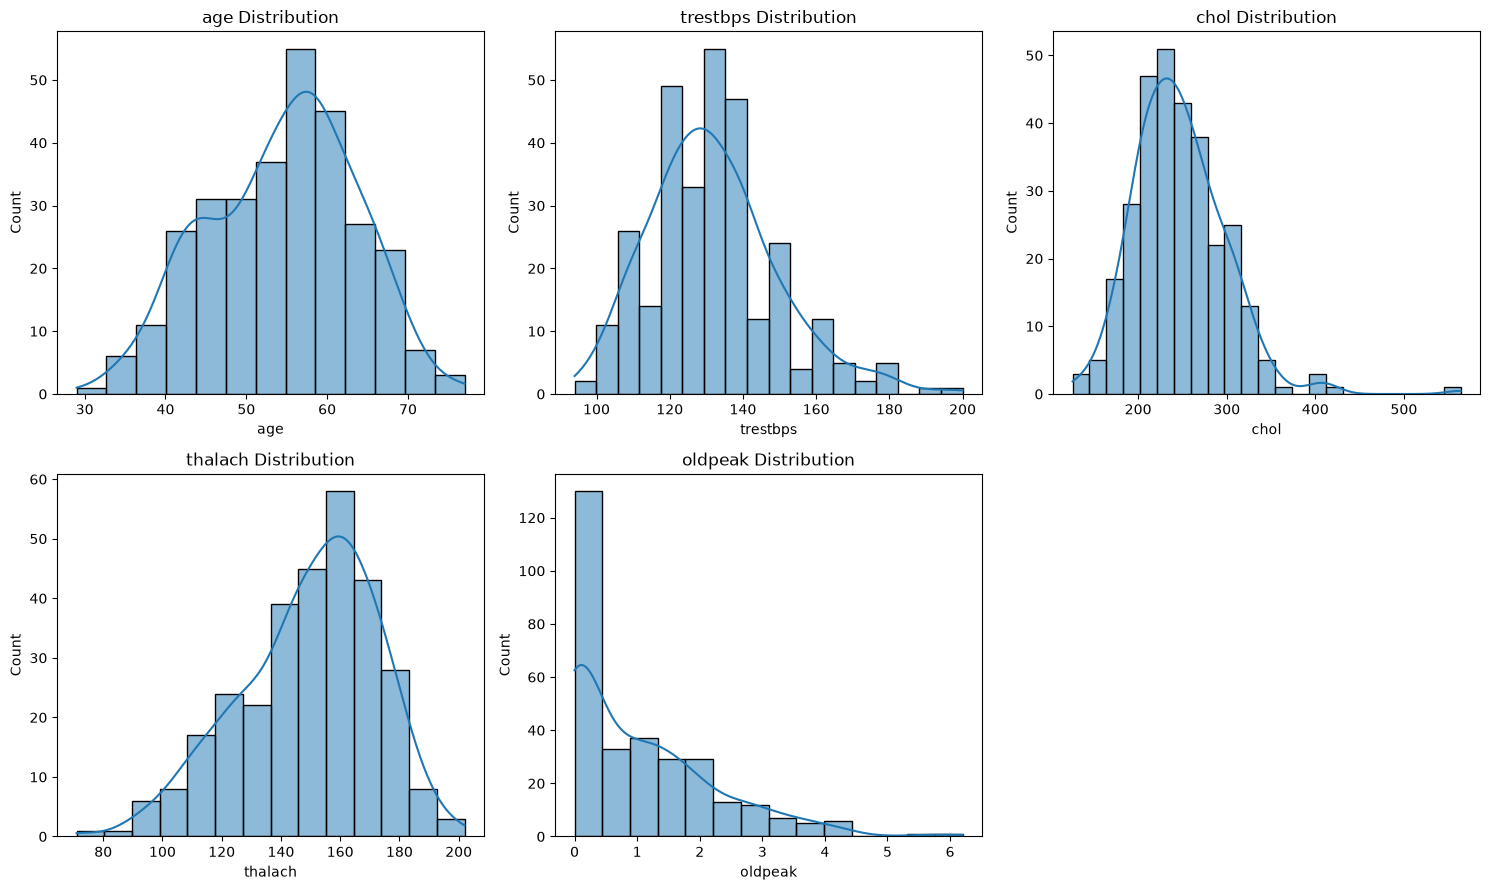

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), numerical_features):
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        ax=ax
    )
    
    ax.set_title(f"{feature} Distribution")
    ax.set_xlabel(feature)
    ax.set_ylabel("Count")

# Hide unused sixth subplot
axes.flatten()[-1].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../screenshots/eda_numerical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

In [24]:
for feature in categorical_features:
    print(f"\n{feature}")
    print(df[feature].value_counts(dropna=False).sort_index())


sex
sex
0     97
1    206
Name: count, dtype: int64

cp
cp
1     23
2     50
3     86
4    144
Name: count, dtype: int64

fbs
fbs
0    258
1     45
Name: count, dtype: int64

restecg
restecg
0    151
1      4
2    148
Name: count, dtype: int64

exang
exang
0    204
1     99
Name: count, dtype: int64

slope
slope
1    142
2    140
3     21
Name: count, dtype: int64

ca
ca
0.0    176
1.0     65
2.0     38
3.0     20
NaN      4
Name: count, dtype: int64

thal
thal
3.0    166
6.0     18
7.0    117
NaN      2
Name: count, dtype: int64


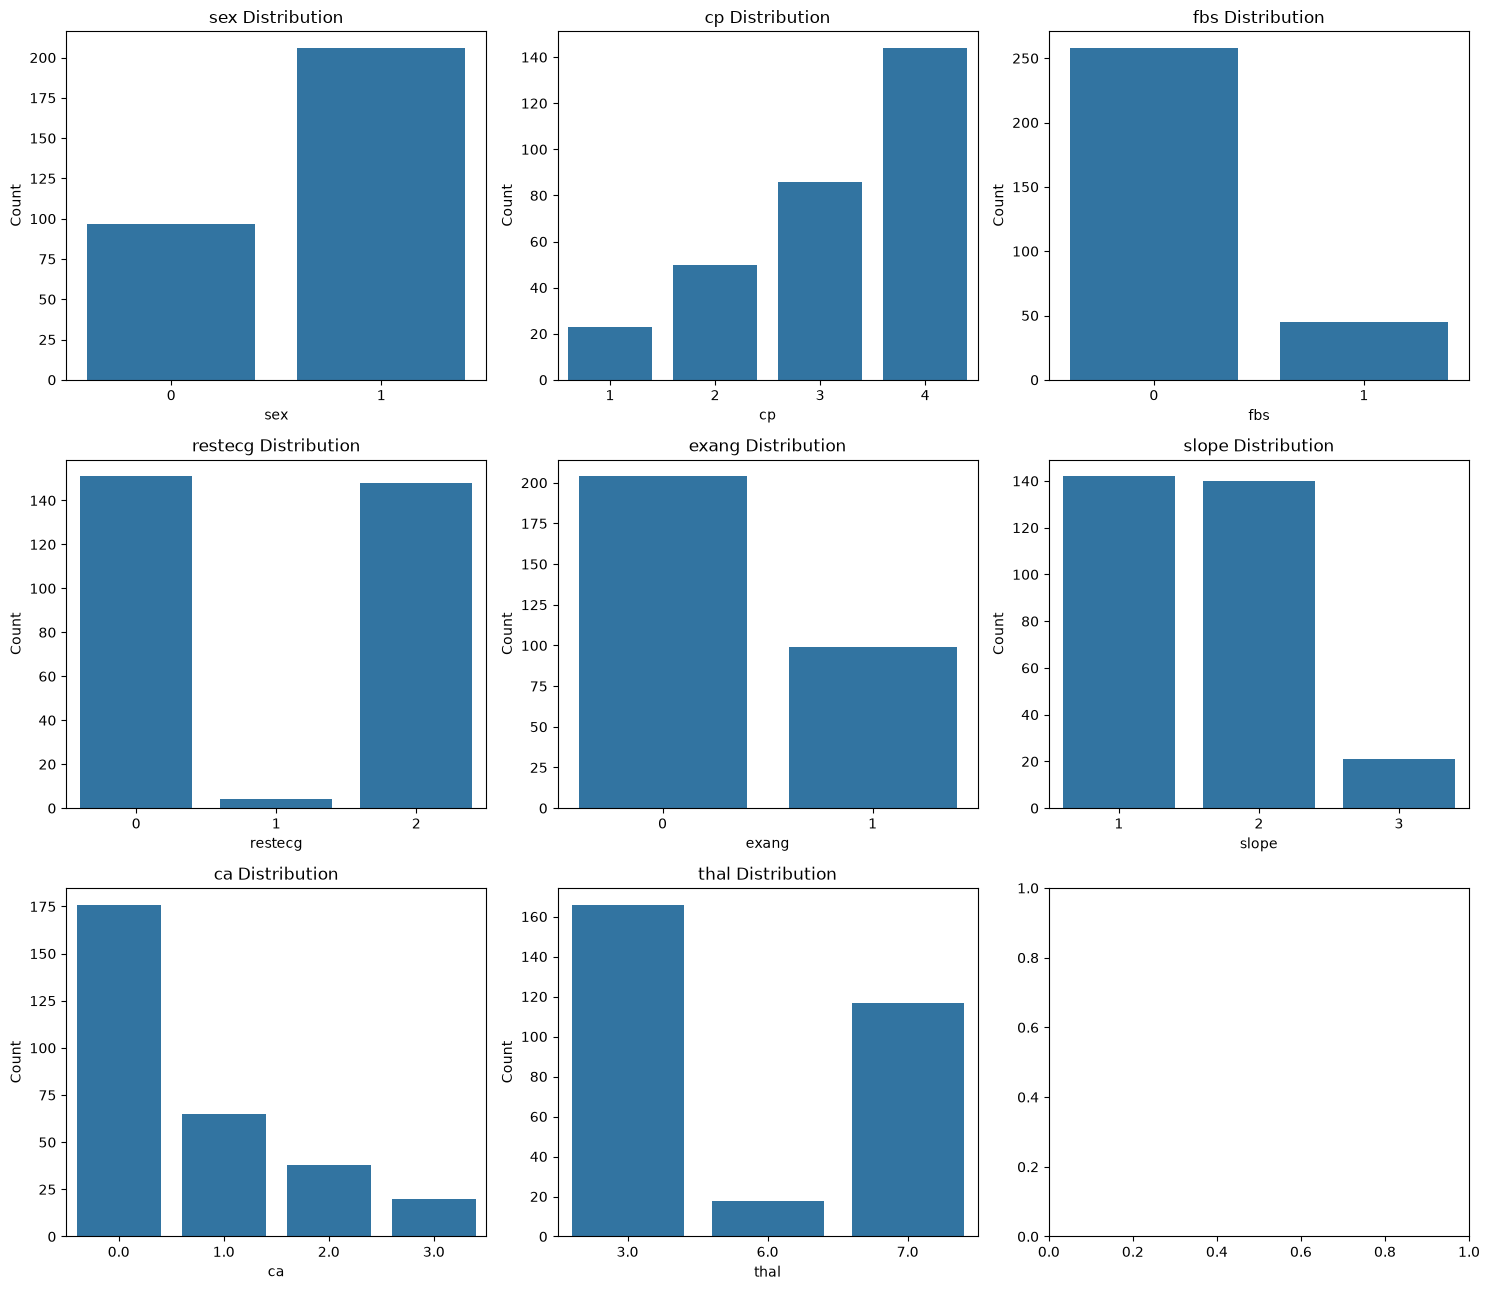

In [25]:
fig, axes = plt.subplots(3, 3, figsize=(15, 13))

for ax, feature in zip(axes.flatten(), categorical_features):
    sns.countplot(
        data=df,
        x=feature,
        ax=ax
    )
    
    ax.set_title(f"{feature} Distribution")
    ax.set_xlabel(feature)
    ax.set_ylabel("Count")

plt.tight_layout()

plt.savefig(
    "../screenshots/eda_categorical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

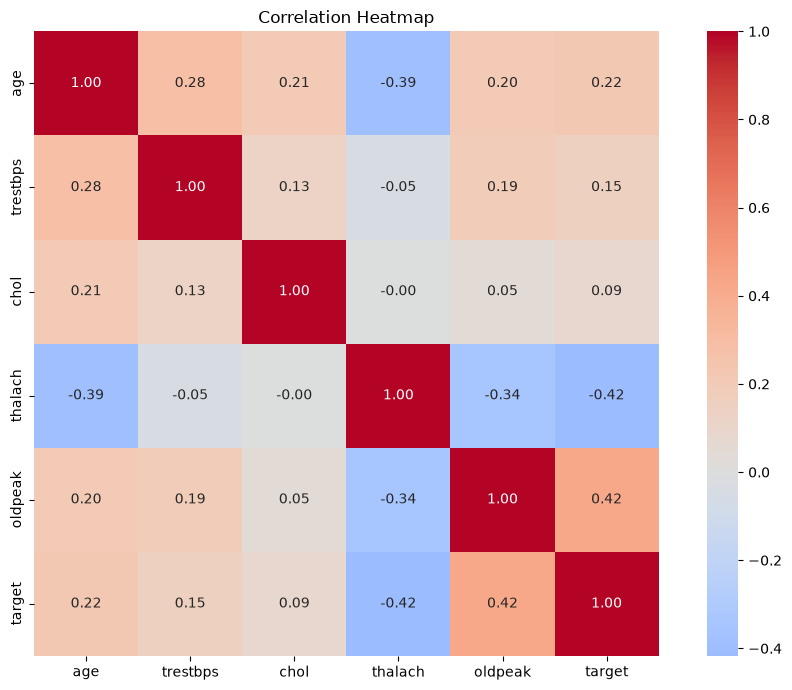

In [26]:
correlation_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
    "target"
]

corr = df[correlation_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.savefig(
    "../screenshots/eda_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

C:\Users\intum\AppData\Local\Temp\ipykernel_2704\2339153914.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["No Disease", "Disease"])
C:\Users\intum\AppData\Local\Temp\ipykernel_2704\2339153914.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["No Disease", "Disease"])
C:\Users\intum\AppData\Local\Temp\ipykernel_2704\2339153914.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["No Disease", "Disease"])
C:\Users\intum\AppData\Local\Temp\ipykernel_2704\2339153914.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_t

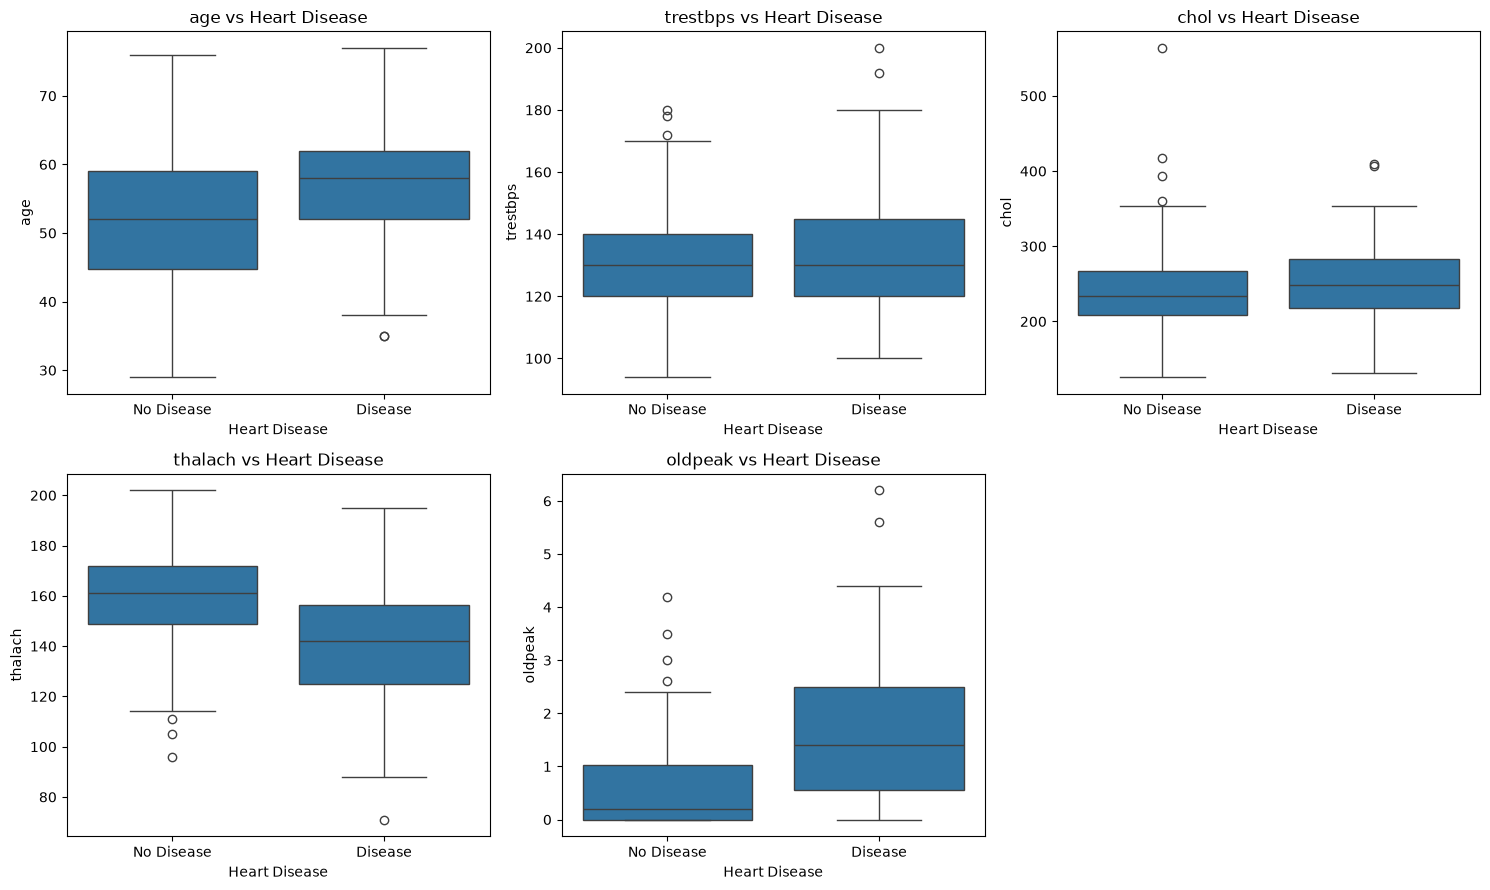

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), numerical_features):
    sns.boxplot(
        data=df,
        x="target",
        y=feature,
        ax=ax
    )
    
    ax.set_title(f"{feature} vs Heart Disease")
    ax.set_xlabel("Heart Disease")
    ax.set_ylabel(feature)
    
    ax.set_xticklabels(["No Disease", "Disease"])

axes.flatten()[-1].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../screenshots/eda_numeric_vs_target.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

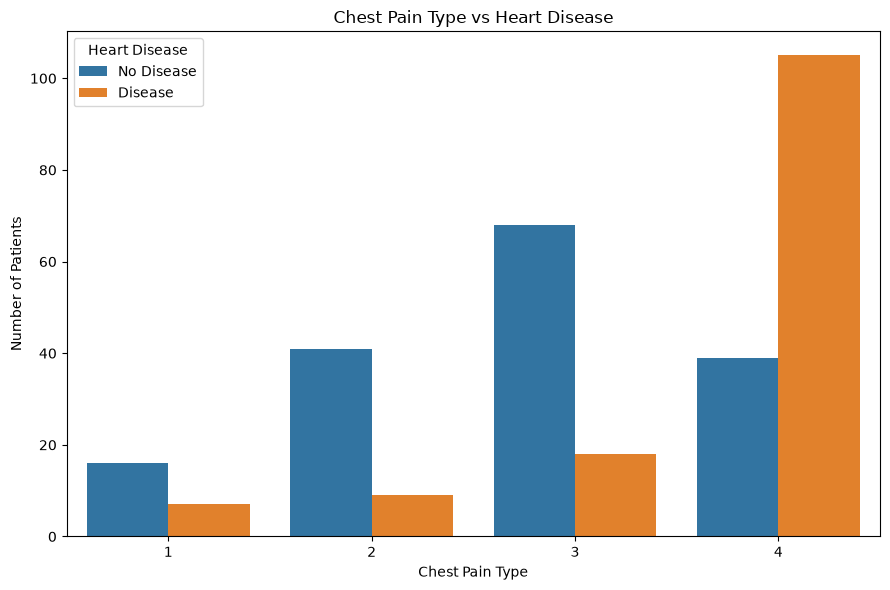

In [28]:
plt.figure(figsize=(9, 6))

sns.countplot(
    data=df,
    x="cp",
    hue="target"
)

plt.title("Chest Pain Type vs Heart Disease")
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Patients")

plt.legend(
    title="Heart Disease",
    labels=["No Disease", "Disease"]
)

plt.tight_layout()

plt.savefig(
    "../screenshots/eda_cp_vs_target.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

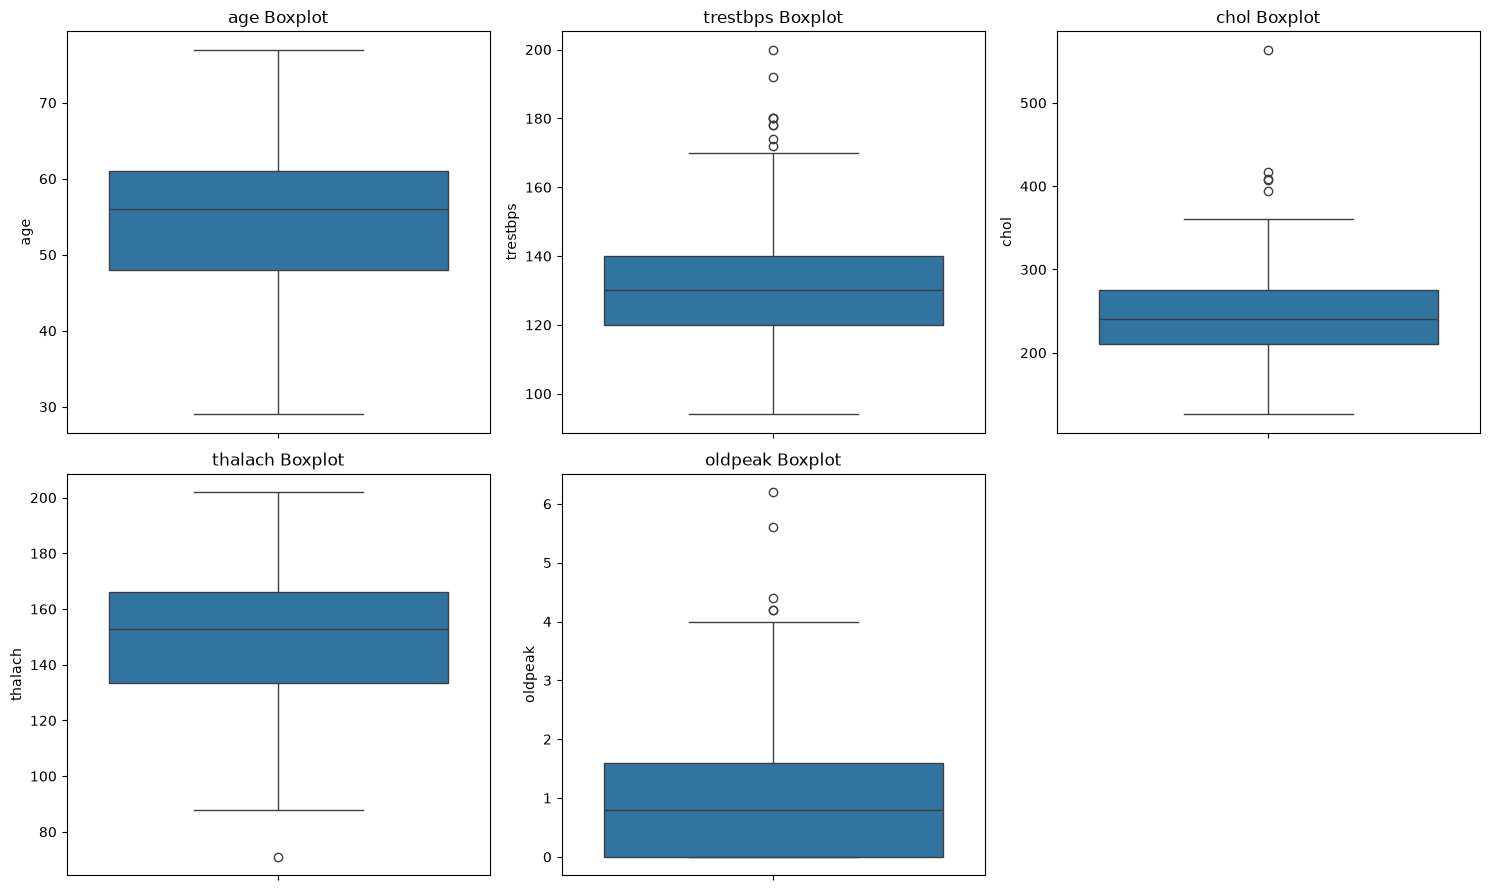

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), numerical_features):
    sns.boxplot(
        data=df,
        y=feature,
        ax=ax
    )
    
    ax.set_title(f"{feature} Boxplot")

axes.flatten()[-1].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../screenshots/eda_outliers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
eda_summary = pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique()
})

eda_summary

,Feature,Data Type,Missing Values,Unique Values
age,age,int64,0,41
sex,sex,int64,0,2
cp,cp,int64,0,4
trestbps,trestbps,int64,0,50
chol,chol,int64,0,152
fbs,fbs,int64,0,2
restecg,restecg,int64,0,3
thalach,thalach,int64,0,91
exang,exang,int64,0,2
oldpeak,oldpeak,float64,0,40


In [31]:
target_summary = pd.DataFrame({
    "Class": df["target"].value_counts().sort_index().index,
    "Count": df["target"].value_counts().sort_index().values,
    "Percentage": (
        df["target"]
        .value_counts(normalize=True)
        .sort_index()
        .values * 100
    )
})

target_summary

,Class,Count,Percentage
0,0,164,54.125413
1,1,139,45.874587


In [32]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000,1.000000


In [33]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

# Binary target:
# 0 = No Disease
# 1 = Disease
df["target"] = (df["num"] > 0).astype(int)

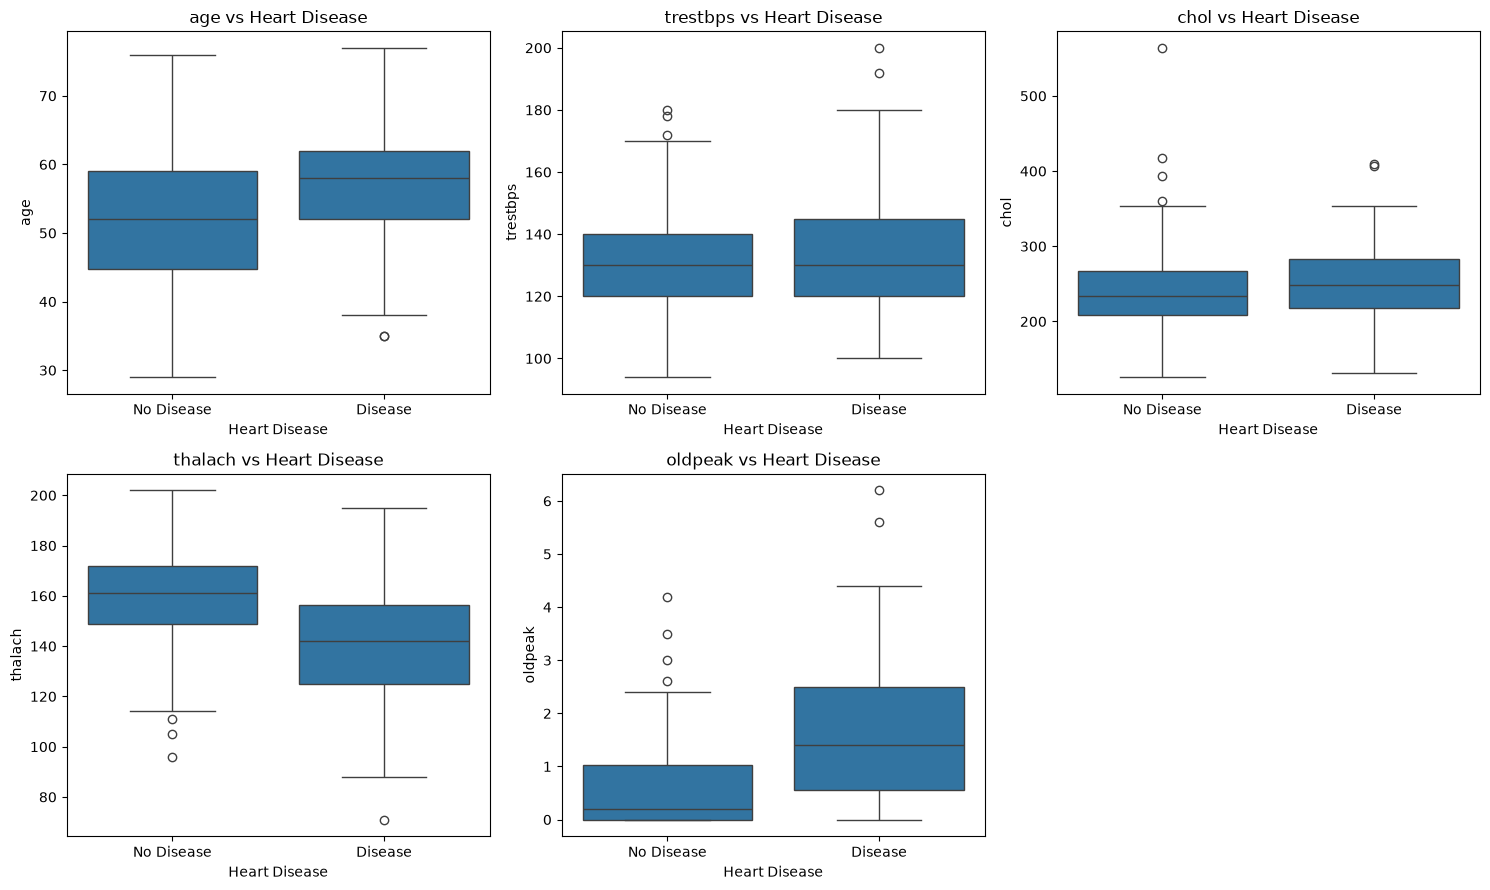

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), numerical_features):

    sns.boxplot(
        data=df,
        x="target",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} vs Heart Disease")
    ax.set_xlabel("Heart Disease")
    ax.set_ylabel(feature)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No Disease", "Disease"])

# Hide the unused 6th plot
axes.flatten()[-1].set_visible(False)

plt.tight_layout()

# Save for your assignment/report
plt.savefig(
    "../screenshots/eda_numeric_vs_target.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Numerical Features vs Heart Disease

The boxplot analysis shows differences in the distributions of several
numerical features across the two target classes. The most noticeable
separation is observed for `thalach` and `oldpeak`. The disease group
shows a lower median maximum heart rate (`thalach`) and a higher median
`oldpeak`. Age also shows a higher median in the disease group.

Resting blood pressure (`trestbps`) and cholesterol (`chol`) exhibit
substantial overlap between the two classes. Several potential outliers
are visible across the numerical variables. These observations are
retained at this stage because statistical outlier status alone does not
indicate invalid data.

In [35]:
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

In [36]:
for feature in categorical_features:
    print(f"\n{'='*40}")
    print(f"{feature}")
    print(df[feature].value_counts(dropna=False).sort_index())


sex
sex
0     97
1    206
Name: count, dtype: int64

cp
cp
1     23
2     50
3     86
4    144
Name: count, dtype: int64

fbs
fbs
0    258
1     45
Name: count, dtype: int64

restecg
restecg
0    151
1      4
2    148
Name: count, dtype: int64

exang
exang
0    204
1     99
Name: count, dtype: int64

slope
slope
1    142
2    140
3     21
Name: count, dtype: int64

ca
ca
0.0    176
1.0     65
2.0     38
3.0     20
NaN      4
Name: count, dtype: int64

thal
thal
3.0    166
6.0     18
7.0    117
NaN      2
Name: count, dtype: int64


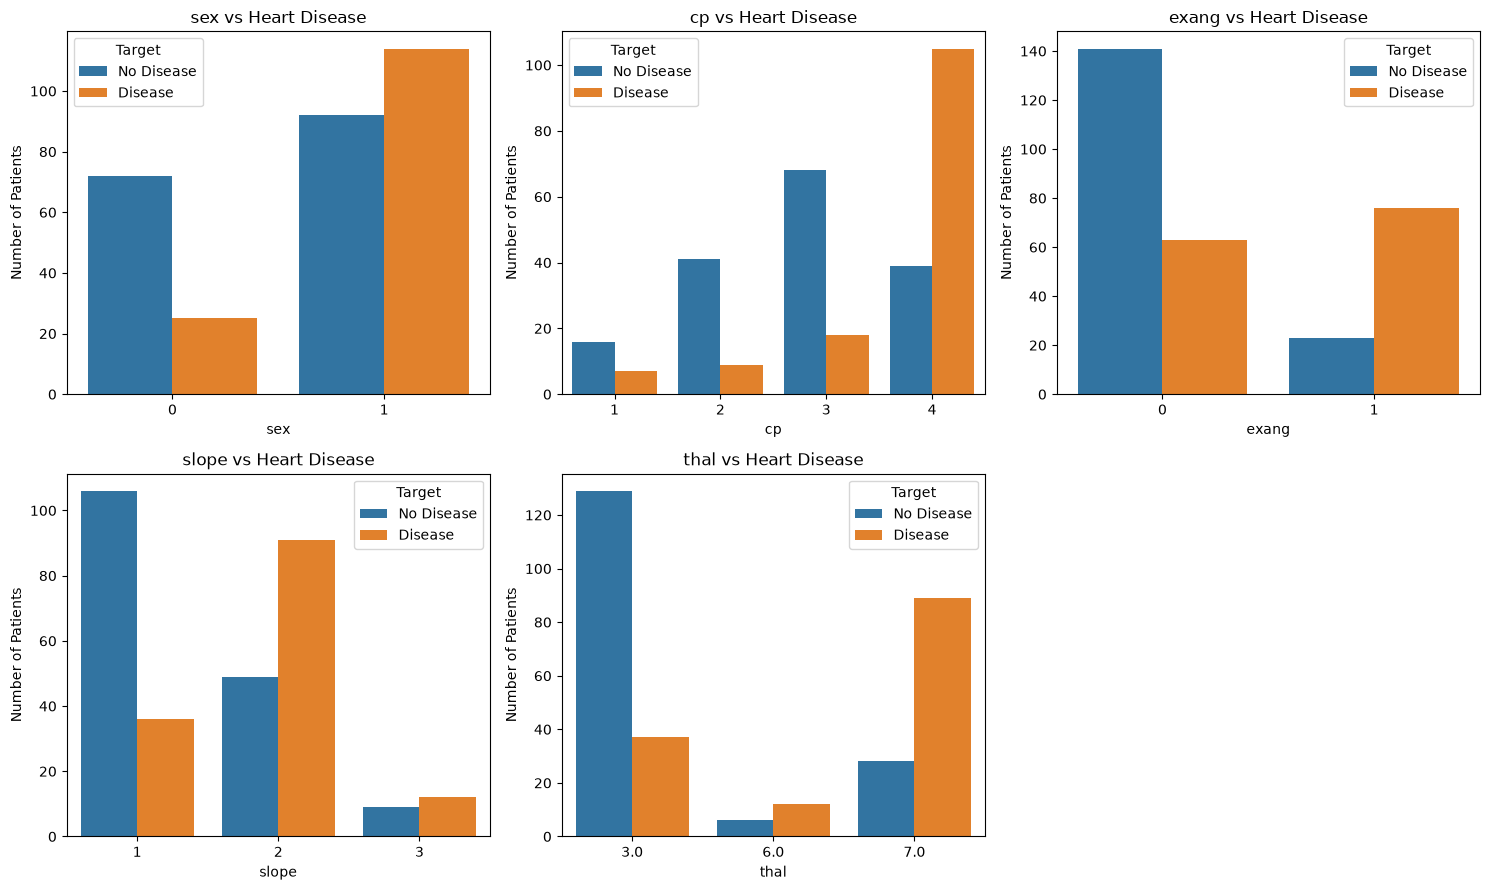

In [37]:
features_to_plot = [
    "sex",
    "cp",
    "exang",
    "slope",
    "thal"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), features_to_plot):

    sns.countplot(
        data=df,
        x=feature,
        hue="target",
        ax=ax
    )

    ax.set_title(f"{feature} vs Heart Disease")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Patients")

    # Make legend readable
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(
        handles,
        ["No Disease", "Disease"],
        title="Target"
    )

axes.flatten()[-1].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../screenshots/eda_categorical_vs_target.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
processed_df = df.copy()

# Convert original UCI target to binary target
processed_df["target"] = (
    processed_df["num"] > 0
).astype(int)

# Remove original multiclass target
processed_df.drop(columns=["num"], inplace=True)

print("Processed dataset shape:")
print(processed_df.shape)

print("\nColumns:")
print(processed_df.columns.tolist())

print("\nMissing values:")
print(processed_df.isnull().sum())

Processed dataset shape:
(303, 14)

Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [39]:
from pathlib import Path

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

In [40]:
processed_path = (
    processed_dir /
    "heart_disease_clean.csv"
)

processed_df.to_csv(
    processed_path,
    index=False
)

print(f"Saved processed dataset to: {processed_path}")

Saved processed dataset to: ..\data\processed\heart_disease_clean.csv


In [41]:
validation_df = pd.read_csv(processed_path)

print("Shape:", validation_df.shape)

print("\nColumns:")
print(validation_df.columns.tolist())

print("\nMissing values:")
print(validation_df.isnull().sum())

print("\nTarget distribution:")
print(validation_df["target"].value_counts().sort_index())

Shape: (303, 14)

Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Target distribution:
target
0    164
1    139
Name: count, dtype: int64


In [42]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [45]:
checks = {
    "age outside 0-100": ((df["age"] < 0) | (df["age"] > 100)).sum(),
    "trestbps <= 0": (df["trestbps"] <= 0).sum(),
    "chol <= 0": (df["chol"] <= 0).sum(),
    "thalach <= 0": (df["thalach"] <= 0).sum(),
    "oldpeak < 0": (df["oldpeak"] < 0).sum()
}

for check, count in checks.items():
    print(f"{check}: {count}")

age outside 0-100: 0
trestbps <= 0: 0
chol <= 0: 0
thalach <= 0: 0
oldpeak < 0: 0


In [46]:
# Create a copy of the original EDA dataframe
processed_df = df.copy()

# Convert UCI's original target:
# 0 = no disease
# 1-4 = disease
processed_df["target"] = (processed_df["num"] > 0).astype(int)

# Remove the original multiclass target
processed_df.drop(columns=["num"], inplace=True)

print("Processed dataset shape:", processed_df.shape)

print("\nColumns:")
print(processed_df.columns.tolist())

print("\nMissing values:")
print(processed_df.isnull().sum())

Processed dataset shape: (303, 14)

Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [47]:
from pathlib import Path

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

print("Processed data directory ready:", processed_dir)

Processed data directory ready: ..\data\processed


In [48]:
processed_path = processed_dir / "heart_disease_clean.csv"

processed_df.to_csv(
    processed_path,
    index=False
)

print(f"Processed dataset saved to: {processed_path}")

Processed dataset saved to: ..\data\processed\heart_disease_clean.csv


In [49]:
validation_df = pd.read_csv(processed_path)

print("Shape:", validation_df.shape)

print("\nColumns:")
print(validation_df.columns.tolist())

print("\nMissing values:")
print(validation_df.isnull().sum())

print("\nTarget distribution:")
print(validation_df["target"].value_counts().sort_index())

Shape: (303, 14)

Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Target distribution:
target
0    164
1    139
Name: count, dtype: int64


In [50]:
assert validation_df.shape == (303, 14)

assert "target" in validation_df.columns

assert "num" not in validation_df.columns

assert validation_df["target"].isin([0, 1]).all()

assert validation_df["target"].value_counts().sum() == 303

print("✅ Processed dataset validation passed!")

✅ Processed dataset validation passed!


In [51]:
print("=" * 60)
print("PHASE 2 — DATASET SUMMARY")
print("=" * 60)

print(f"Total records       : {len(processed_df)}")
print(f"Total features      : {processed_df.shape[1] - 1}")
print(f"Target classes      : {processed_df['target'].nunique()}")
print(f"Missing ca values   : {processed_df['ca'].isna().sum()}")
print(f"Missing thal values : {processed_df['thal'].isna().sum()}")
print(f"Duplicate rows      : {processed_df.duplicated().sum()}")

print("\nTarget distribution:")
print(processed_df["target"].value_counts().sort_index())

print("\nPhase 2 completed successfully.")

PHASE 2 — DATASET SUMMARY
Total records       : 303
Total features      : 13
Target classes      : 2
Missing ca values   : 4
Missing thal values : 2
Duplicate rows      : 0

Target distribution:
target
0    164
1    139
Name: count, dtype: int64

Phase 2 completed successfully.
